In [133]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [134]:
cluster =  pd.read_csv("grova3.csv",header = None)

In [135]:
cluster.columns = ["X","Y","Vx","Vy","Vz"]

In [136]:
cluster

,X,Y,Vx,Vy,Vz
0,37.25,11.84,2.85,3.97,2.27
1,43.07,18.47,3.37,1.49,3.06
2,16.67,4.52,2.82,1.48,1.03
3,49.34,18.92,1.01,0.39,2.05
4,20.17,42.56,1.86,2.05,0.32
...,...,...,...,...,...
10995,31.95,62.38,1.00,5.06,5.23
10996,25.27,28.61,4.28,5.68,4.17
10997,20.03,42.89,4.31,5.00,3.85
10998,33.47,56.72,5.48,5.11,5.38


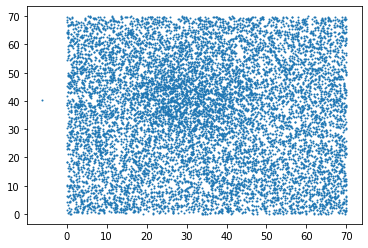

In [137]:
#2D - Coordinates
plt.scatter(cluster["X"],cluster["Y"], s = 1)

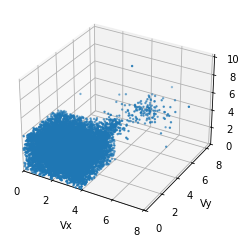

In [196]:
# 3D - How are velocities correlated?
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

X_0, Y_0, Z_0 = [0, 0], [0, 0], [0, 0]
ax.set_xlim([0, max(cluster["Vx"])])
ax.set_ylim([0, max(cluster["Vy"])])
ax.set_zlim([0, max(cluster["Vz"])])
ax.set_xlabel('Vx')
ax.set_ylabel('Vy')
ax.set_zlabel('Vz')

ax.scatter(cluster["Vx"],cluster["Vy"],cluster["Vz"], s = 2)

In [139]:
cluster.describe()

,X,Y,Vx,Vy,Vz
count,11000.000000,11000.000000,11000.000000,11000.000000,11000.000000
mean,34.384104,35.689065,2.249892,2.234625,2.238075
std,19.575234,19.458192,1.348376,1.359960,1.352417
min,-6.150000,0.000000,0.000000,0.000000,0.000000
25%,18.300000,19.390000,1.130000,1.110000,1.110000
50%,33.765000,36.795000,2.200000,2.180000,2.210000
75%,50.602500,51.412500,3.280000,3.290000,3.280000
max,69.990000,70.000000,8.450000,8.580000,10.270000


[Text(0.5, 0, 'Vy'), Text(0, 0.5, 'Vz')]

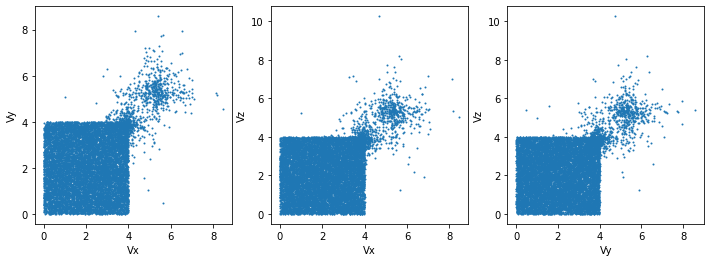

In [140]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster["Vx"],cluster["Vy"], s = 1)
ax1.set(xlabel="Vx", ylabel="Vy")
ax2.scatter(cluster["Vx"],cluster["Vz"], s = 1)
ax2.set(xlabel="Vx", ylabel="Vz")
ax3.scatter(cluster["Vy"],cluster["Vz"], s = 1)
ax3.set(xlabel="Vy", ylabel="Vz")

In [141]:
# სამივე ნახაზში ვხედავ ვარსკვლავებს რომლებიც არიან აუცილებლად გროვის წევრი. 

In [142]:
first_cutoff = 4

# ამოვიღო ინდექსები ამ ვარსკვლავების.
first_cluster = cluster[((cluster["Vx"] >= first_cutoff) & (cluster["Vy"] >= first_cutoff)) | ((cluster["Vx"] >= first_cutoff) & (cluster["Vz"] >= first_cutoff)) | ((cluster["Vy"] >= first_cutoff) & (cluster["Vz"] >= first_cutoff))]

# ჯერჯერობით ამოვარჩიე 396 ვარსკვლავი
first_cluster.shape[0]

627

In [143]:
first_cluster

,X,Y,Vx,Vy,Vz
10000,26.70,34.81,3.32,4.08,4.05
10001,36.24,30.57,3.90,4.03,4.40
10007,41.43,46.71,3.97,4.09,4.51
10008,48.35,45.96,4.48,4.59,4.25
10009,28.11,38.73,4.24,4.51,4.32
...,...,...,...,...,...
10995,31.95,62.38,1.00,5.06,5.23
10996,25.27,28.61,4.28,5.68,4.17
10997,20.03,42.89,4.31,5.00,3.85
10998,33.47,56.72,5.48,5.11,5.38


(0.0, 33.0)

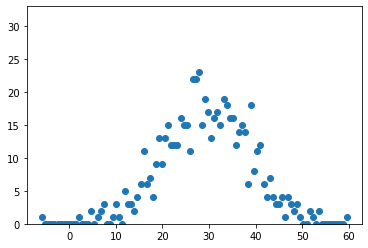

In [144]:
bins = 100

uniform_hist_X = np.histogram(first_cluster["X"], bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 31.0)

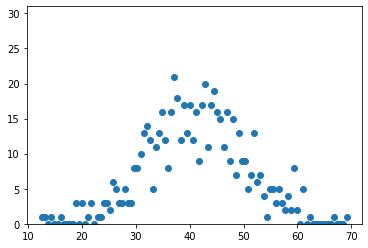

In [145]:
uniform_hist_Y = np.histogram(first_cluster["Y"], bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

In [146]:
def gauss(x, A, mu, sigma):
    return A * np.exp(-(x - mu)**2/(2*sigma**2))

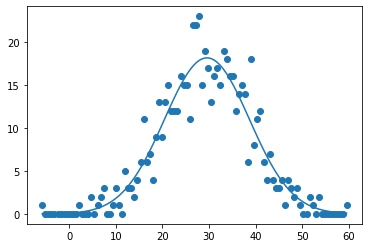

In [147]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), first_cluster["X"].mean(), first_cluster["X"].std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

In [148]:
x_center = popt[1]

In [149]:
residuals = uniform_hist_X[0] - gauss(centers, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_X[0] - uniform_hist_X[0].mean())**2)
r2 = 1 - ss_res / ss_tot
r2

0.9070575079577522

0.8435684958876736

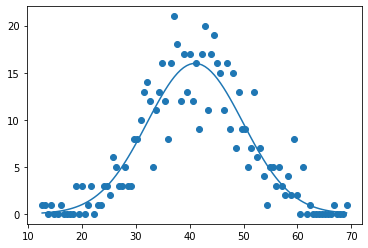

In [150]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_Y[0], p0=[uniform_hist_Y[0].max(), first_cluster["Y"].mean(), first_cluster["Y"].std()])
plt.scatter(centers1, uniform_hist_Y[0])
plt.plot(centers1, gauss(centers1, *popt))
residuals = uniform_hist_Y[0] - gauss(centers1, *popt)
ss_res = np.sum(residuals**2)
ss_tot = np.sum((uniform_hist_Y[0] - uniform_hist_Y[0].mean())**2)
r2_y = 1 - ss_res / ss_tot
r2_y

In [151]:
y_center = popt[1]

In [152]:
print(x_center, y_center)

29.56618302528333 41.00870348414524


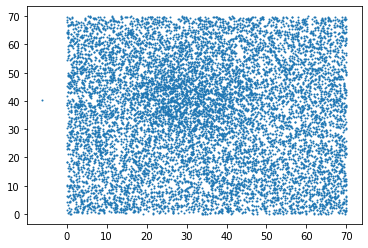

In [153]:
plt.scatter(cluster["X"],cluster["Y"], s = 1)

In [154]:
n = first_cluster.shape[0]

r = 2
n_circ = 50
t = np.linspace(-10*np.pi,10*np.pi,300)

final_radius = r*np.sqrt(50)

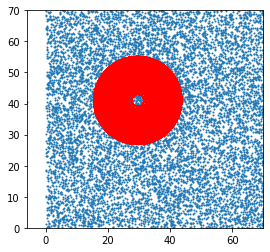

In [155]:
plt.scatter(cluster["X"], cluster["Y"], s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())
plt.gca().set_aspect("equal")

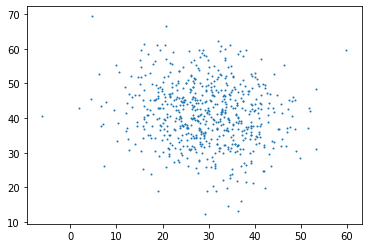

In [156]:
plt.scatter(first_cluster["X"], first_cluster["Y"], s = 1)

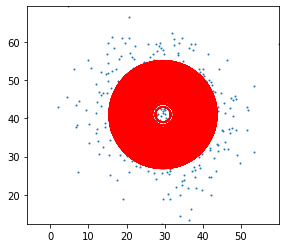

In [157]:
plt.scatter(first_cluster["X"], first_cluster["Y"], s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x_center+R*np.cos(t),y_center+R*np.sin(t),c = "r")
plt.xlim(first_cluster["X"].min(), first_cluster["X"].max())
plt.ylim(first_cluster["Y"].min(), first_cluster["Y"].max())
plt.gca().set_aspect("equal")

In [158]:
counts = [0] * n_circ
selected = []   # original index labels of stars inside the circles

for i in range(n_circ):
    for j in range(n):
        d2 = (first_cluster["X"].iloc[j] - x_center)**2 + (first_cluster["Y"].iloc[j] - y_center)**2
        if (r*np.sqrt(i))**2 < d2 <= (r*np.sqrt(i+1))**2:
            counts[i] += 1
            selected.append(first_cluster.index[j])

first_cluster_final = first_cluster.loc[selected]

In [159]:
sum(counts)

#წრეწირების დახმარებით, ჩამოვედი 365-ზე.

446

In [160]:
n_all = cluster.shape[0]
counts_full = [0] * n_circ

for i in range(n_circ):
    for j in range(n_all):
        if (r*np.sqrt(i))**2<(cluster["X"].iloc[j]-x_center)**2 + (cluster["Y"].iloc[j]-y_center)**2<=(r*np.sqrt(i+1))**2:
            counts_full[i] = counts_full[i] + 1

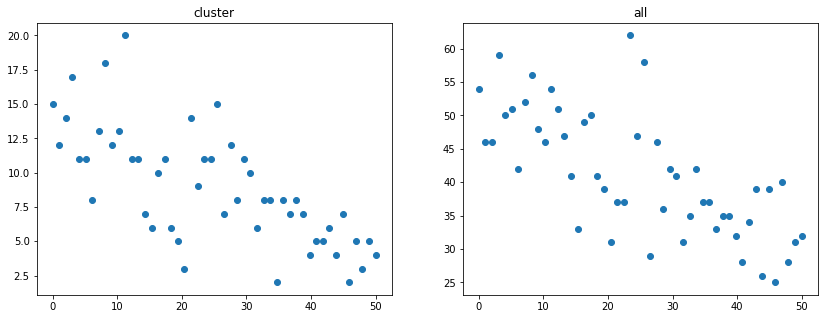

In [161]:
fig, (ax1,ax2) = plt.subplots(1, 2, figsize = (14,5))
ax1.scatter(np.linspace(0,n_circ,n_circ),counts)
ax1.set_title("cluster")
ax2.scatter(np.linspace(0,n_circ,n_circ),counts_full)
ax2.set_title("all")

plt.show()

In [162]:
# უნდა გამოვყო ვარსკვლავები, რომლებიც შერეულია.

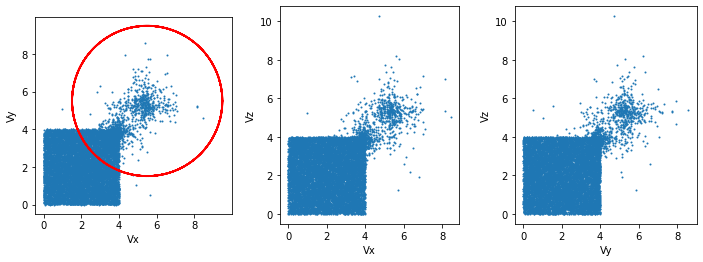

In [163]:
centerr = 5.5
radiuss = 4
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster["Vx"],cluster["Vy"], s = 1)
ax1.set(xlabel="Vx", ylabel="Vy")
ax1.plot(centerr + radiuss*np.cos(t), centerr + radiuss*np.sin(t),c = "r")

ax2.scatter(cluster["Vx"],cluster["Vz"], s = 1)
ax2.set(xlabel="Vx", ylabel="Vz")
ax3.scatter(cluster["Vy"],cluster["Vz"], s = 1)
ax3.set(xlabel="Vy", ylabel="Vz")

for ax in (ax1, ax2, ax3):
    ax.set_aspect("equal")

In [164]:
additional_idx = []   # original index labels of stars inside the velocity circle
for j in range(n_all):
    d2 = (cluster["Vx"].iloc[j] - centerr)**2 + (cluster["Vy"].iloc[j] - centerr)**2
    if d2 <= radiuss**2:
        additional_idx.append(cluster.index[j])

additional_cluster = cluster.loc[additional_idx]

In [165]:
len(additional_cluster)

2924

In [166]:
# remove the stars that are already in first_cluster (compared by their original index)
additional_cluster = additional_cluster[~additional_cluster.index.isin(first_cluster.index)]
len(additional_cluster)

2301

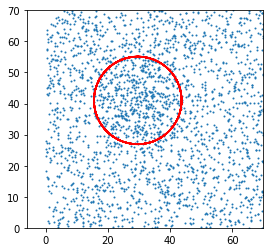

In [167]:
plt.scatter(additional_cluster["X"], additional_cluster["Y"], s = 1)

plt.plot(x_center+final_radius*np.cos(t),y_center+final_radius*np.sin(t),c = "r")
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())

plt.gca().set_aspect("equal")

In [168]:
final_additional_idx = []   # original index labels (same numbers as in cluster)
for j in range(len(additional_cluster)):
    d2 = (additional_cluster["X"].iloc[j] - x_center)**2 + (additional_cluster["Y"].iloc[j] - y_center)**2
    if d2 < final_radius**2:
        final_additional_idx.append(additional_cluster.index[j])

final_additional_first = additional_cluster.loc[final_additional_idx]

In [169]:
first_cluster_stars = pd.concat([
    first_cluster_final.assign(group="main"),
    final_additional_first.assign(group="additional"),
])


In [170]:
first_cluster_stars = first_cluster_stars.sort_index()

In [171]:
first_cluster_stars

,X,Y,Vx,Vy,Vz,group
27,28.06,51.31,2.38,3.25,3.51,additional
44,25.15,46.87,3.33,2.49,1.08,additional
80,35.92,30.30,2.43,3.57,3.19,additional
116,38.89,48.59,3.32,3.12,0.53,additional
137,36.11,48.61,3.99,2.03,3.09,additional
...,...,...,...,...,...,...
10993,27.31,35.15,6.57,5.25,5.36,main
10994,27.00,51.19,5.05,6.62,5.00,main
10996,25.27,28.61,4.28,5.68,4.17,main
10997,20.03,42.89,4.31,5.00,3.85,main


(0.0, 70.0)

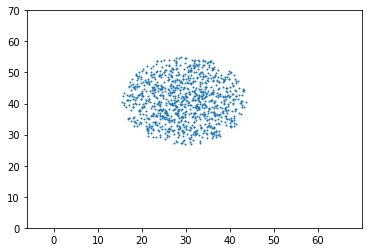

In [172]:
plt.scatter(first_cluster_stars["X"], first_cluster_stars["Y"], s = 1)
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())

In [173]:
cutoff = 4 - 1
first_cluster = first_cluster_stars[((first_cluster_stars["Vx"] >= cutoff) & (first_cluster_stars["Vy"] >= cutoff)) & (first_cluster_stars["Vz"] >= cutoff)] 
first_cluster

,X,Y,Vx,Vy,Vz,group
573,22.14,30.56,3.69,3.94,3.05,additional
1058,40.85,45.78,3.89,3.03,3.57,additional
1867,34.27,43.64,3.51,3.13,3.92,additional
2628,17.38,41.03,3.84,3.10,3.72,additional
3200,18.99,42.03,3.09,3.42,3.73,additional
...,...,...,...,...,...,...
10993,27.31,35.15,6.57,5.25,5.36,main
10994,27.00,51.19,5.05,6.62,5.00,main
10996,25.27,28.61,4.28,5.68,4.17,main
10997,20.03,42.89,4.31,5.00,3.85,main


(0.0, 70.0)

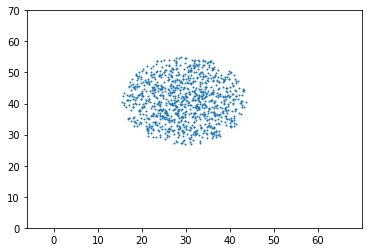

In [174]:
plt.scatter(first_cluster_stars["X"], first_cluster_stars["Y"], s = 1)
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())

In [175]:
first_cluster.head()

,X,Y,Vx,Vy,Vz,group
573,22.14,30.56,3.69,3.94,3.05,additional
1058,40.85,45.78,3.89,3.03,3.57,additional
1867,34.27,43.64,3.51,3.13,3.92,additional
2628,17.38,41.03,3.84,3.10,3.72,additional
3200,18.99,42.03,3.09,3.42,3.73,additional


In [176]:
first_cluster.shape

(684, 6)

In [177]:
correct = 0
all = first_cluster.shape[1]
for idx, rows in first_cluster.iterrows():
    if idx >= 10000:
        correct += 1

correct


670

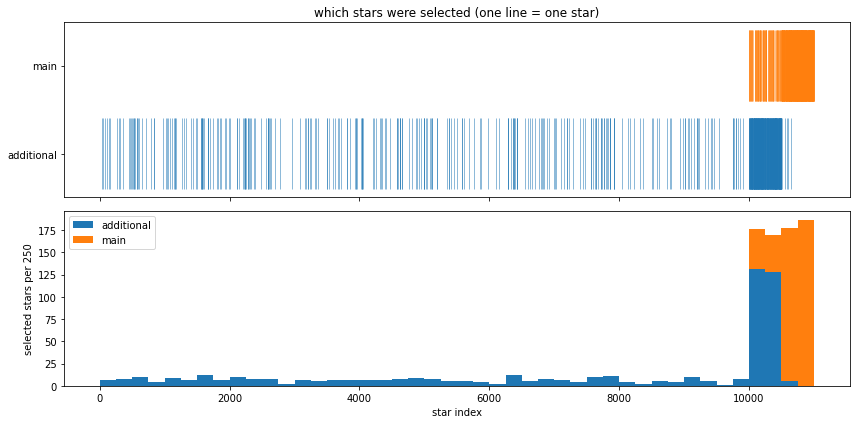

In [178]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
groups = sorted(first_cluster_stars["group"].unique())

# 1) barcode: one vertical line per selected star
for row, (name, grp) in enumerate(first_cluster_stars.groupby("group")):
    ax1.vlines(grp.index, row, row + 0.8, lw=0.5, color=f"C{row}")
ax1.set_yticks([0.4, 1.4])
ax1.set_yticklabels(groups)
ax1.set_title("which stars were selected (one line = one star)")

# 2) histogram: how many selected stars in each block of 250 indexes
bins = np.arange(0, len(cluster) + 250, 250)
ax2.hist([grp.index for _, grp in first_cluster_stars.groupby("group")],
         bins=bins, stacked=True, label=groups)
ax2.set(xlabel="star index", ylabel="selected stars per 250")
ax2.legend()

plt.tight_layout()
plt.show()


In [179]:
cluster = cluster[~cluster.index.isin(first_cluster_stars.index)]
len(cluster)

10023

In [180]:
cluster

,X,Y,Vx,Vy,Vz
0,37.25,11.84,2.85,3.97,2.27
1,43.07,18.47,3.37,1.49,3.06
2,16.67,4.52,2.82,1.48,1.03
3,49.34,18.92,1.01,0.39,2.05
4,20.17,42.56,1.86,2.05,0.32
...,...,...,...,...,...
10987,28.54,58.87,5.33,4.68,5.45
10988,17.27,52.90,4.00,4.79,5.70
10991,47.11,42.65,5.51,5.43,4.83
10995,31.95,62.38,1.00,5.06,5.23


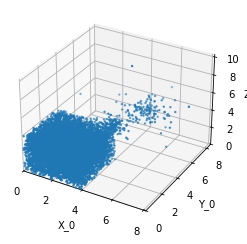

In [181]:
# 3D - How are velocities correlated?
fig = plt.figure()
ax = fig.add_subplot(projection='3d')

X_0, Y_0, Z_0 = [0, 0], [0, 0], [0, 0]
ax.set_xlim([0, max(cluster["Vx"])])
ax.set_ylim([0, max(cluster["Vy"])])
ax.set_zlim([0, max(cluster["Vz"])])
ax.set_xlabel('X_0')
ax.set_ylabel('Y_0')
ax.set_zlabel('Z_0')

ax.scatter(cluster["Vx"],cluster["Vy"],cluster["Vz"], s = 2)

[Text(0.5, 0, 'Vy'), Text(0, 0.5, 'Vz')]

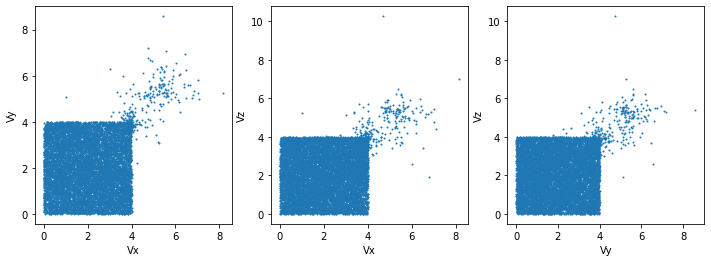

In [182]:
fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize = (12,4))
ax1.scatter(cluster["Vx"],cluster["Vy"], s = 1)
ax1.set(xlabel="Vx", ylabel="Vy")
ax2.scatter(cluster["Vx"],cluster["Vz"], s = 1)
ax2.set(xlabel="Vx", ylabel="Vz")
ax3.scatter(cluster["Vy"],cluster["Vz"], s = 1)
ax3.set(xlabel="Vy", ylabel="Vz")

In [183]:
second_cutoff = 4

# ამოვიღო ინდექსები ამ ვარსკვლავების.
second_cluster = cluster[((cluster["Vx"] >= second_cutoff) & (cluster["Vy"] >= second_cutoff)) | ((cluster["Vx"] >= second_cutoff) & (cluster["Vz"] >= second_cutoff)) | ((cluster["Vy"] >= second_cutoff) & (cluster["Vz"] >= second_cutoff))]

# ჯერჯერობით ამოვარჩიე 396 ვარსკვლავი
second_cluster.shape[0]

181

(0.0, 18.0)

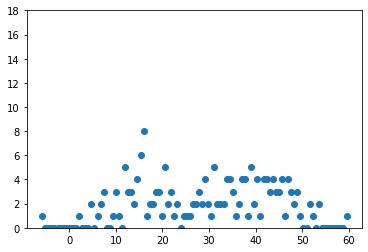

In [184]:
bins = 100

uniform_hist_X = np.histogram(second_cluster["X"], bins)
edges = uniform_hist_X[1]
centers = (edges[:-1] + edges[1:])/2
plt.scatter(centers, uniform_hist_X[0])
plt.ylim(0,max(uniform_hist_X[0]) + 10)

(0.0, 18.0)

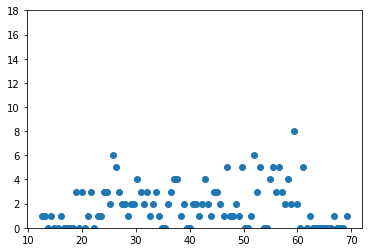

In [185]:
uniform_hist_Y = np.histogram(second_cluster["Y"], bins)
edges1 = uniform_hist_Y[1]
centers1 = (edges1[:-1] + edges1[1:])/2
plt.scatter(centers1, uniform_hist_Y[0])
plt.ylim(0,max(uniform_hist_Y[0]) + 10)

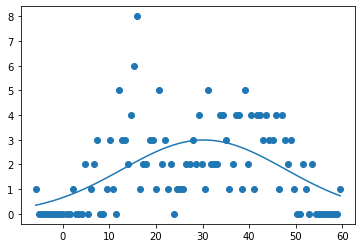

In [186]:
popt, pcov = curve_fit(gauss, centers, uniform_hist_X[0], p0=[uniform_hist_X[0].max(), second_cluster["X"].mean(), second_cluster["X"].std()])
plt.scatter(centers, uniform_hist_X[0])
plt.plot(centers, gauss(centers, *popt))

In [187]:
x2_center = popt[1]

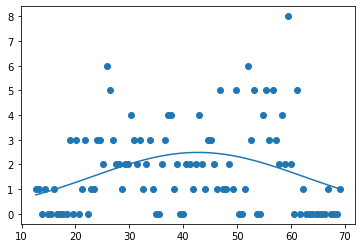

In [188]:
popt, pcov = curve_fit(gauss, centers1, uniform_hist_Y[0], p0=[uniform_hist_Y[0].max(), second_cluster["Y"].mean(), second_cluster["Y"].std()])
plt.scatter(centers1, uniform_hist_Y[0])
plt.plot(centers1, gauss(centers1, *popt))

In [189]:
y2_center = popt[1]

In [190]:
print(x_center, y_center)

29.56618302528333 41.00870348414524


In [191]:
print(x2_center, y2_center)

30.279221641702126 42.72667566849631


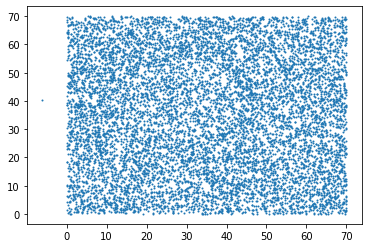

In [192]:
plt.scatter(cluster["X"],cluster["Y"], s = 1)

In [193]:
n = second_cluster.shape[0]

r = 3
n_circ = 50
t = np.linspace(-10*np.pi,10*np.pi,300)

final_radius = r*np.sqrt(50)

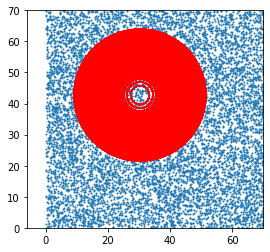

In [194]:
plt.scatter(cluster["X"], cluster["Y"], s = 1)

for i in range(n_circ):
    R = r*np.sqrt(i+1)
    plt.plot(x2_center+R*np.cos(t),y2_center+R*np.sin(t),c = "r")
plt.xlim(cluster["X"].min(), cluster["X"].max())
plt.ylim(cluster["Y"].min(), cluster["Y"].max())
plt.gca().set_aspect("equal")

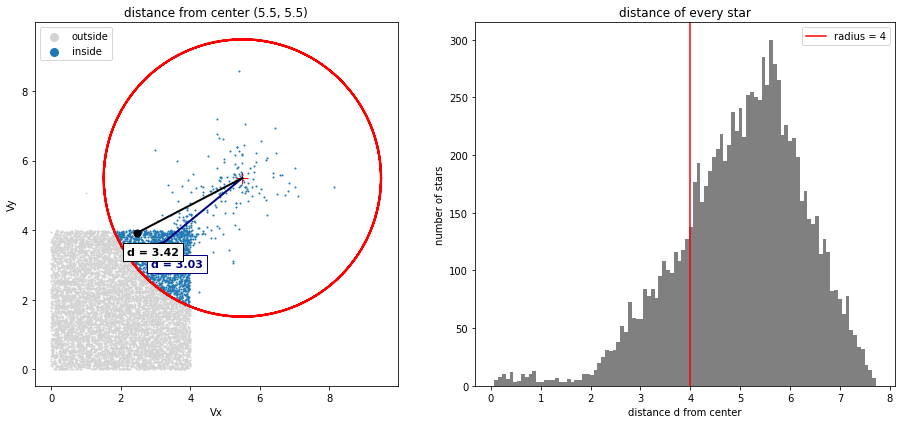

In [195]:
d2 = (cluster["Vx"] - centerr)**2 + (cluster["Vy"] - centerr)**2
d = np.sqrt(d2)
inside = d2 <= radiuss**2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

# left: the stars, the circle, and the distance of two example stars
ax1.scatter(cluster["Vx"][~inside], cluster["Vy"][~inside], s=1, c="lightgray", label="outside")
ax1.scatter(cluster["Vx"][inside], cluster["Vy"][inside], s=1, c="tab:blue", label="inside")
ax1.plot(centerr + radiuss*np.cos(t), centerr + radiuss*np.sin(t), c="r")
ax1.plot(centerr, centerr, "r+", ms=12)

example_in = (d - 1.1).abs()[(cluster["Vx"] < 3.2) & (cluster["Vy"] < 3.6)].idxmin()
example_out = (d - 2.6).abs()[(cluster["Vx"] < 2.5) & (cluster["Vy"] > 2.5)].idxmin()

for j, col in [(example_in, "navy"), (example_out, "black")]:
    vx, vy = cluster.loc[j, "Vx"], cluster.loc[j, "Vy"]
    ax1.plot([centerr, vx], [centerr, vy], c=col, lw=2)   # the distance line
    ax1.plot(vx, vy, "o", c=col, ms=7)
    ax1.annotate(f"d = {d[j]:.2f}", (vx, vy), xytext=(-10, -22), textcoords="offset points",
                 color=col, fontsize=11, weight="bold", bbox=dict(fc="white", ec=col))

ax1.set(xlabel="Vx", ylabel="Vy", title=f"distance from center ({centerr}, {centerr})")
ax1.set_aspect("equal")
ax1.legend(markerscale=8, loc="upper left")

# right: distance of every star
ax2.hist(d, bins=100, color="gray")
ax2.axvline(radiuss, c="r", label=f"radius = {radiuss}")
ax2.set(xlabel="distance d from center", ylabel="number of stars", title="distance of every star")
ax2.legend()

plt.tight_layout()
plt.show()
